# SurvCraft — competing risks from latent distributions

In many applications an individual can experience **one of several mutually exclusive events**, and the first one
to happen prevents the others from being observed: death from different causes, relapse vs. treatment-related death,
failure of a machine through different components. These are **competing risks**.

The event of each sample is then encoded with an **integer cause code**: `0` for right censoring and `k ≥ 1` for an
event of cause `k`.

## The latent-distribution model

SurvCraft models competing risks through **latent distributions**: for every cause `k` a survival module describes the
time $T_k$ at which that event *would* happen if no other cause existed, with survival $S_k(t)$ and hazard $h_k(t)$.
The causes compete, and the observed event is the first one, $T=\min_k T_k$. The cumulative incidence functions
(CIFs) $F_k(t)=P(T\le t,\ \text{cause}=k)$ then solve

$$\frac{dF_k(t)}{dt} = h_k(t)\Bigl(1-\sum_j F_j(t)\Bigr),\qquad F_k(0)=0,$$

and the all-cause survival has the closed form $S(t)=1-\sum_k F_k(t)=\prod_k S_k(t)$.

In practice:
- `CompetingRisksSurvivalAdapter(latents=[...])` combines any survival adapters, one per cause;
- `CompetingRisksLikelihoodLoss` fits all latent distributions jointly. The likelihood only needs the subdensities
  $h_k(t)S(t)$ and $S(t)$, which are exact products of latent outputs, so training never integrates the ODE;
- the CIFs are obtained by integrating the ODE on a time grid (mode `"cif"`).

## What this notebook does

1. **Simulate** a competing-risks dataset with SurvCraft's own `SurvivalSimulator`, one latent distribution per cause,
   with **linear feature effects**.
2. **Fit** a model with the matching specification.
3. **Compare** the reconstructed quantities with the ground truth: parameters, latent survival curves, cumulative
   incidences for single individuals, and population-level incidences against a nonparametric estimate.

The causes and their distributions are set in a single list, `CAUSES`, below. The example uses two causes, but you can
swap the distributions or change the number of causes and run everything else unchanged.

In [16]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.model_selection import train_test_split
from sksurv.nonparametric import cumulative_incidence_competing_risks

import survcraft.adapters as ad
from survcraft.loss_modules import CompetingRisksLikelihoodLoss
from survcraft.survival_modules import CompetingRisksSurvivalModule

torch.manual_seed(0)
rng = np.random.default_rng(0)

## Configuration

Each entry of `CAUSES` defines one competing cause, in cause-code order: entry `k-1` is cause `k`.

- `survival` is the latent distribution, as any trainable survival adapter class from `survcraft.adapters`. The same
  class is used to simulate the data and to fit the model.
- `shift` is the constant added to that cause's linear feature map in the simulator. It moves the typical event times
  of the cause, and with them how often it occurs first.

In [94]:
CAUSES = [
    {"survival": ad.WeibullSurvivalAdapter, "shift": 0.},  #'shift' is a parameter that shifts the distribution to the right (positive) or left (negative) and therefore controls the 
    {"survival": ad.WeibullSurvivalAdapter, "shift": 0.3},
]

n_samples, n_features = 1000, 2
horizon = 5.0  # end of follow-up: later events are administratively censored

n_causes = len(CAUSES)
CAUSE_NAMES = {
    k: f"cause {k} ({c['survival'].__name__.removesuffix('SurvivalAdapter')})" for k, c in enumerate(CAUSES, 1)
}

# One color per cause, in a fixed order and used consistently in every plot; line style separates truth from fit.
PALETTE = ["#257de0", "#f47230", "#00b894", "#f2a600", "#ee7fac", "#008a17", "#6a4ce2", "#ec4647"]
assert n_causes <= len(PALETTE), "add colors to PALETTE for more causes"
CAUSE_COLORS = dict(zip(range(1, n_causes + 1), PALETTE))
NEUTRAL = "#7a7a7a"
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e3e3e3",
    "grid.linewidth": 0.8,
    "lines.linewidth": 2,
})

## 1. Simulating the latent event times

`SurvivalSimulator` samples outcomes from a fixed SurvCraft model. We build one simulator per cause, each with a
`LinearFunctionInputAdapter`, which maps the features to the raw (unconstrained) distribution parameters through a fixed
affine map

$$\text{raw} = X\,W + s,$$

with random weights $W$ (scaled by `multiplier`) and the cause's constant `shift` $s$. The survival module then maps
the raw parameters to its constrained parameters. The feature effects are therefore **linear on the raw parameter
scale**.

In [95]:
X = rng.normal(size=(n_samples, n_features)).astype(np.float32)

simulators = [
    ad.SurvivalSimulator(
        input=ad.LinearFunctionInputAdapter(mode="random", multiplier=0.6, shift=c["shift"], seed=k),
        survival=c["survival"](),
    )
    for k, c in enumerate(CAUSES, 1)
]

# Each simulator samples on a fine grid: an event is placed at the midpoint of the interval where it falls,
# and samples whose latent time exceeds the last grid point are censored at the horizon.
sim_grid = np.linspace(0.0, horizon, 2001)
latent_outcomes = [sim.simulate(X, sim_grid, seed=k) for k, sim in enumerate(simulators, 1)]

for k, y_k in enumerate(latent_outcomes, 1):
    print(f"{CAUSE_NAMES[k]}: latent time within follow-up for {y_k['event'].mean():.1%} of individuals")

cause 1 (Weibull): latent time within follow-up for 97.5% of individuals
cause 2 (Weibull): latent time within follow-up for 98.9% of individuals


### Letting the causes compete

The simulations are **independent latent times** for the same individuals. The observed outcome is the earliest one.
On top of the administrative censoring at the horizon, we add independent uniform censoring, so the model also has to
handle censoring in the middle of the follow-up. If several latent times fall in the same grid interval (rare) the tie
goes to the lowest cause code.

In [96]:
# latent times, infinite when beyond the follow-up: shape (n_samples, n_causes)
latent_times = np.stack([np.where(y_k["event"], y_k["time"], np.inf) for y_k in latent_outcomes], axis=1)
t_first = latent_times.min(axis=1)
first_cause = latent_times.argmin(axis=1) + 1

t_censor = np.minimum((rng.uniform(0.0, 1., n_samples)**2)*1.2*horizon, horizon) # 2*horizon is to avoid too many ties at the horizon, and regulates the fraction of censored samples


event = np.where(t_first <= t_censor, first_cause, 0)
observed_time = np.minimum(t_first, t_censor)

# integer cause codes in the event field: 0 = censored, k = cause k
y = np.zeros(n_samples, dtype=[("event", "i8"), ("time", "f4")])
y["event"], y["time"] = event, observed_time

counts = pd.Series(event).map({0: "censored", **CAUSE_NAMES}).value_counts()
pd.DataFrame({"count": counts, "fraction": (counts / n_samples).round(3)})

,count,fraction
cause 1 (Weibull),457,0.457
cause 2 (Weibull),326,0.326
censored,217,0.217


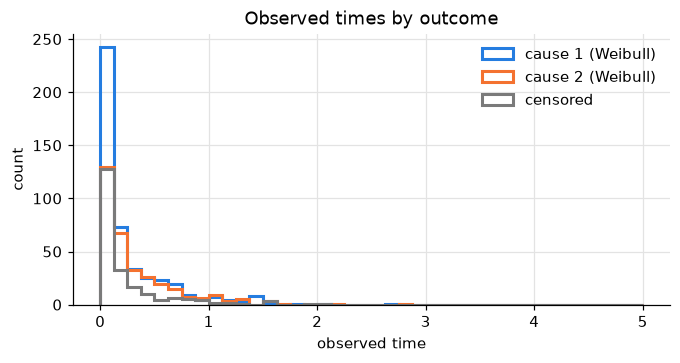

In [97]:
fig, ax = plt.subplots(figsize=(7, 3.2))
bins = np.linspace(0, horizon, 41)
outcomes = [(k, CAUSE_COLORS[k], CAUSE_NAMES[k]) for k in CAUSE_NAMES] + [(0, NEUTRAL, "censored")]
for code_, color, label in outcomes:
    ax.hist(observed_time[event == code_], bins=bins, histtype="step", color=color, linewidth=2, label=label)
ax.set(xlabel="observed time", ylabel="count", title="Observed times by outcome")
ax.legend(frameon=False)
plt.show()

## 2. The ground-truth model

To compare the fit with the truth *exactly*, rather than only through the sampled data, we assemble the
data-generating process as a SurvCraft model from the simulators' own modules:

- the input is the fixed linear maps of all causes side by side;
- the survival module is a `CompetingRisksSurvivalModule` combining the latent modules.

This is precisely the model the data come from, and it supports the same prediction modes as the fitted one.

In [98]:
class ConcatInput(torch.nn.Module):
    # applies several input modules to the same features and concatenates their raw parameters
    def __init__(self, *parts):
        super().__init__()
        self.parts = torch.nn.ModuleList(parts)

    def forward(self, x):
        return torch.cat([part(x) for part in self.parts], dim=-1)


true_model = ad.TorchModel(
    input_module=ConcatInput(*[sim.model_.input_module for sim in simulators]),
    survival_module=CompetingRisksSurvivalModule(
        [sim.model_.survival_module for sim in simulators],
        time_grid=torch.linspace(0.0, horizon, 501),
    ),
)


def predict(model, mode, X, times=None):
    # evaluate any TorchModel (truth or fit) on NumPy inputs
    with torch.no_grad():
        out = model(mode, torch.as_tensor(X), None if times is None else torch.as_tensor(times, dtype=torch.float32))
    return out.numpy()

## 3. Fitting the competing-risks model

We fit with the specification matching the data-generating process:

- **input**: `FeedForwardNetAdapter(hidden_sizes=[])`, a single trainable linear layer, the same functional form as the
  simulators' maps;
- **survival**: `CompetingRisksSurvivalAdapter` with one latent of the same class for each cause. The order of
  `latents` defines the cause codes;
- **loss**: `CompetingRisksLikelihoodLoss`. An event of cause $k$ at time $t$ contributes $\log\bigl(h_k(t)S(t)\bigr)$
  and a censored sample contributes $\log S(t)$.

The target is the structured array with integer codes built above; `fit` accepts it directly.

In [99]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y["event"])

predictor = ad.SurvivalPredictor(
    input=ad.FeedForwardNetAdapter(hidden_sizes=[]),
    survival=ad.CompetingRisksSurvivalAdapter(latents=[c["survival"]() for c in CAUSES]),
    loss=CompetingRisksLikelihoodLoss(),
    epochs=200,
    batch_size=256,
    learning_rate=0.01,
    history=True,
)

start = time.perf_counter()
predictor.fit(X_train, y_train, X_test=X_test, y_test=y_test)
print(f"training time: {time.perf_counter() - start:.0f} s")

training time: 15 s


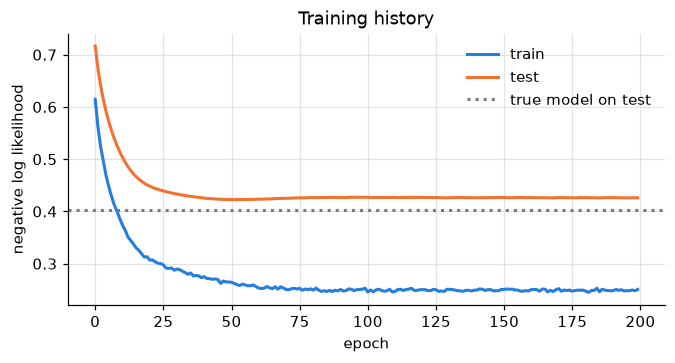

In [100]:
# train_history_ holds, per epoch, the batch training losses and the test losses by loss name
train_loss = [np.mean(batch_losses) for batch_losses, _ in predictor.train_history_]
test_loss = [test["CompetingRisksLikelihoodLoss"] for _, test in predictor.train_history_]
# the fields of a structured array are strided views: copy them before handing them to torch
true_test_loss = CompetingRisksLikelihoodLoss()(
    true_model, torch.as_tensor(X_test),
    torch.as_tensor(y_test["event"].copy()), torch.as_tensor(y_test["time"].copy()),
).item()

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(train_loss, color=PALETTE[0], label="train")
ax.plot(test_loss, color=PALETTE[1], label="test")
ax.axhline(true_test_loss, color=NEUTRAL, linestyle=":", label="true model on test")
ax.set(xlabel="epoch", ylabel="negative log likelihood", title="Training history")
ax.legend(frameon=False)
plt.show()

The test loss should approach the loss of the true model on the same data, which is as good as any model can do on
average.

## 4. Comparing reconstructed and original quantities

### 4.1 Coefficients

The fitted linear layer has the same layout as the ground-truth map: one row per raw parameter, ordered by cause and
then by the parameters of each latent distribution.

In [101]:
def raw_param_names(survival_module):
    # labels of the raw parameters, in the order the latents consume them
    names = []
    for k, latent in enumerate(survival_module.latents.values(), 1):
        for group in latent.params:
            names += [f"cause {k}: {group.name}" + (f"[{j}]" if group.n > 1 else "") for j in range(group.n)]
    return names


def linear_map_table(weights, bias, param_names):
    # one row per raw distribution parameter, one column per feature plus the bias
    table = pd.DataFrame(weights.T, index=param_names, columns=[f"w_x{i + 1}" for i in range(weights.shape[0])])
    table["bias"] = bias
    return table


true_maps = [sim.model_.input_module for sim in simulators]
true_weights = torch.cat([m.linear_params for m in true_maps], dim=1).numpy()
true_bias = np.concatenate([np.full(m.linear_params.shape[1], m.shift) for m in true_maps])

layer = predictor.model_.input_module.layers[0]
fitted_weights = layer.weight.detach().numpy().T
fitted_bias = layer.bias.detach().numpy()

param_names = raw_param_names(true_model.survival_module)
pd.concat(
    {"true": linear_map_table(true_weights, true_bias, param_names),
     "fitted": linear_map_table(fitted_weights, fitted_bias, param_names)},
    axis=1,
).round(3)

true             fitted              
                 w_x1   w_x2 bias   w_x1   w_x2   bias
cause 1: scale  0.455  0.242  0.0  0.469  0.407 -0.264
cause 1: shape  0.168  0.441  0.0  0.102  0.379  0.165
cause 2: scale  0.369  0.382  0.3  0.214  0.434  0.181
cause 2: shape  0.229  0.285  0.3  0.356  0.275  0.434

For distributions whose parameters are identifiable the coefficients should be close to the true ones. Some
parameterizations, however, contain parameters that affect the distribution only through a combination of them. Then
different coefficients describe the same distribution, and the data cannot tell them apart. Coefficients are therefore
not the right measure of reconstruction in general. The comparisons below use the distributions themselves, which are
always identifiable.

### 4.2 Individual latent survivals and cumulative incidences

For three test individuals we compare the latent survival curves $S_k(t)$ (mode `"latent_survival"`) and the
cumulative incidences $F_k(t)$ (mode `"cif"`) with the ground truth. Solid lines are the truth, dashed lines the fit.
Each CIF stays below the corresponding latent failure probability $1-S_k(t)$: the competing causes remove individuals
before the event can happen.

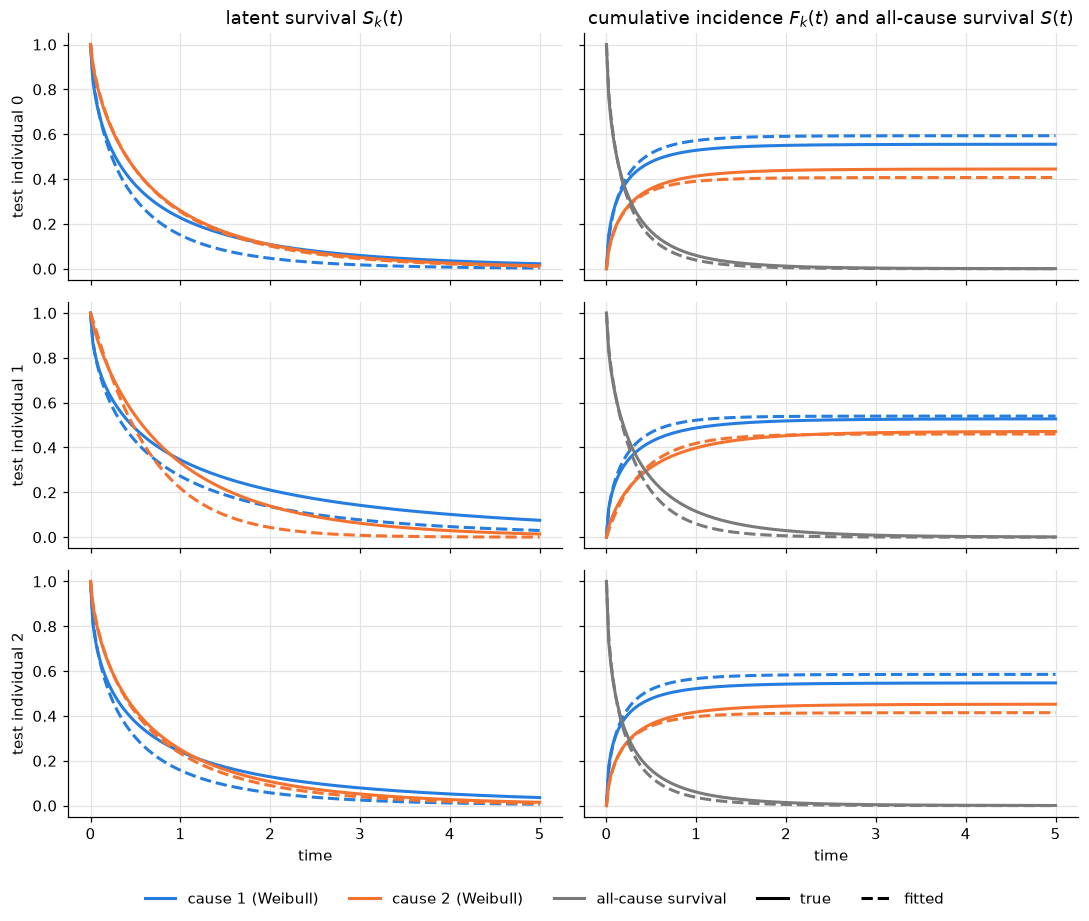

In [102]:
times = np.linspace(0.0, horizon, 201, dtype=np.float32)
examples = [0, 1, 2]

true_latent = predict(true_model, "latent_survival", X_test[examples], times)  # (individuals, times, causes)
fitted_latent = predictor.predict("latent_survival", X_test[examples], times)
true_cif = predict(true_model, "cif", X_test[examples], times)
fitted_cif = predictor.predict("cif", X_test[examples], times)
true_surv = predict(true_model, "survival", X_test[examples], times)
fitted_surv = predictor.predict("survival", X_test[examples], times)

fig, axes = plt.subplots(len(examples), 2, figsize=(10, 2.8 * len(examples)), sharex=True, sharey=True)
for row, i in enumerate(examples):
    for k in CAUSE_NAMES:
        axes[row, 0].plot(times, true_latent[row, :, k - 1], color=CAUSE_COLORS[k])
        axes[row, 0].plot(times, fitted_latent[row, :, k - 1], color=CAUSE_COLORS[k], linestyle="--")
        axes[row, 1].plot(times, true_cif[row, :, k - 1], color=CAUSE_COLORS[k])
        axes[row, 1].plot(times, fitted_cif[row, :, k - 1], color=CAUSE_COLORS[k], linestyle="--")
    axes[row, 1].plot(times, true_surv[row], color=NEUTRAL)
    axes[row, 1].plot(times, fitted_surv[row], color=NEUTRAL, linestyle="--")
    axes[row, 0].set_ylabel(f"test individual {i}")
axes[0, 0].set_title("latent survival $S_k(t)$")
axes[0, 1].set_title("cumulative incidence $F_k(t)$ and all-cause survival $S(t)$")
for ax in axes[-1]:
    ax.set_xlabel("time")

# one shared legend: color identifies the quantity, line style separates truth from fit
handles = [plt.Line2D([], [], color=CAUSE_COLORS[k], label=CAUSE_NAMES[k]) for k in CAUSE_NAMES] + [
    plt.Line2D([], [], color=NEUTRAL, label="all-cause survival"),
    plt.Line2D([], [], color="black", label="true"),
    plt.Line2D([], [], color="black", linestyle="--", label="fitted"),
]
fig.legend(handles=handles, loc="lower center", ncol=min(len(handles), 5), frameon=False)
fig.tight_layout(rect=(0, 0.04 * (1 + (len(handles) - 1) // 5), 1, 1))
plt.show()

### 4.3 Population level, with a nonparametric reference

Averaging the CIFs over the test individuals gives the population cumulative incidence. We compare the true and fitted
averages with the **Aalen–Johansen** estimator computed from the observed test outcomes (from scikit-survival). That
estimator uses no model at all, so it checks the fit against the data rather than against the simulator.

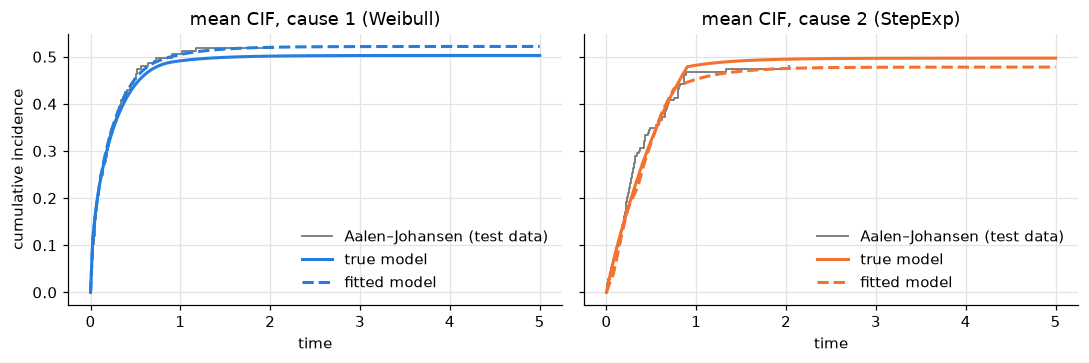

In [89]:
mean_true_cif = predict(true_model, "cif", X_test, times).mean(axis=0)
mean_fitted_cif = predictor.predict("cif", X_test, times).mean(axis=0)
aj_times, aj_cif = cumulative_incidence_competing_risks(y_test["event"], y_test["time"])  # aj_cif[k] = cause k

fig, axes = plt.subplots(1, n_causes, figsize=(5 * n_causes, 3.4), sharey=True, squeeze=False)
for ax, k in zip(axes[0], CAUSE_NAMES):
    ax.step(aj_times, aj_cif[k], where="post", color=NEUTRAL, linewidth=1.2, label="Aalen–Johansen (test data)")
    ax.plot(times, mean_true_cif[:, k - 1], color=CAUSE_COLORS[k], label="true model")
    ax.plot(times, mean_fitted_cif[:, k - 1], color=CAUSE_COLORS[k], linestyle="--", label="fitted model")
    ax.set(xlabel="time", title=f"mean CIF, {CAUSE_NAMES[k]}")
    ax.legend(frameon=False)
axes[0, 0].set_ylabel("cumulative incidence")
fig.tight_layout()
plt.show()

### 4.4 Agreement for every individual

Finally, we compare the true and fitted latent survivals and CIFs at a few time points for all test individuals,
along with the mean absolute error (MAE).

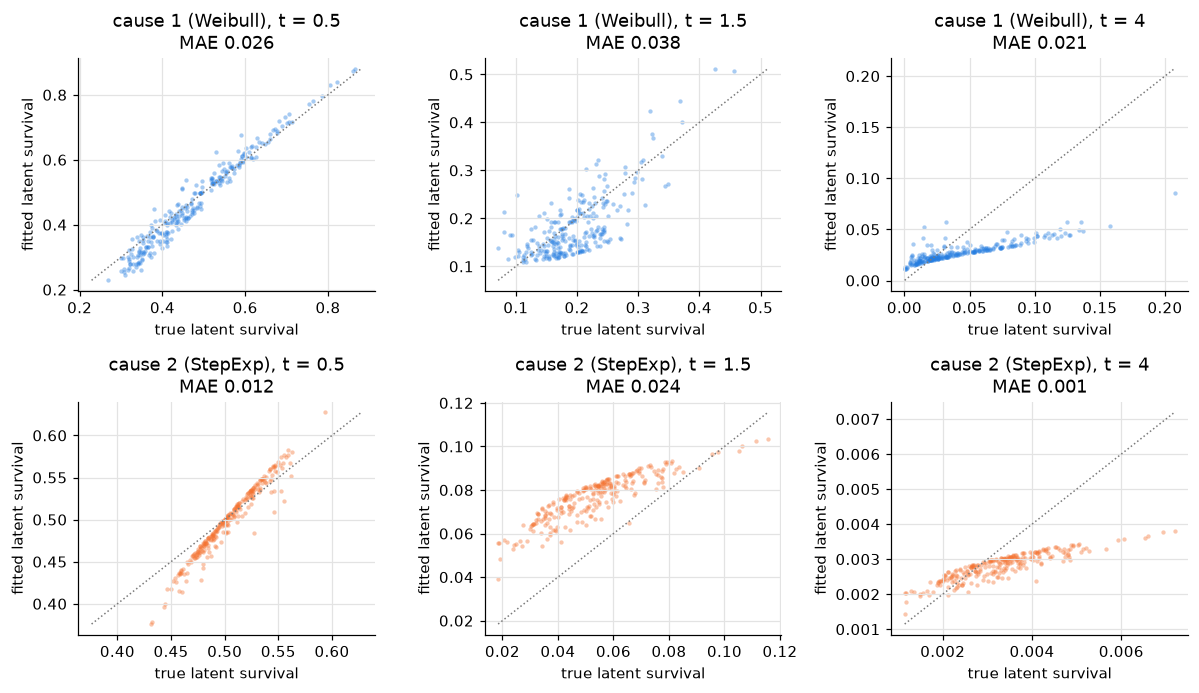

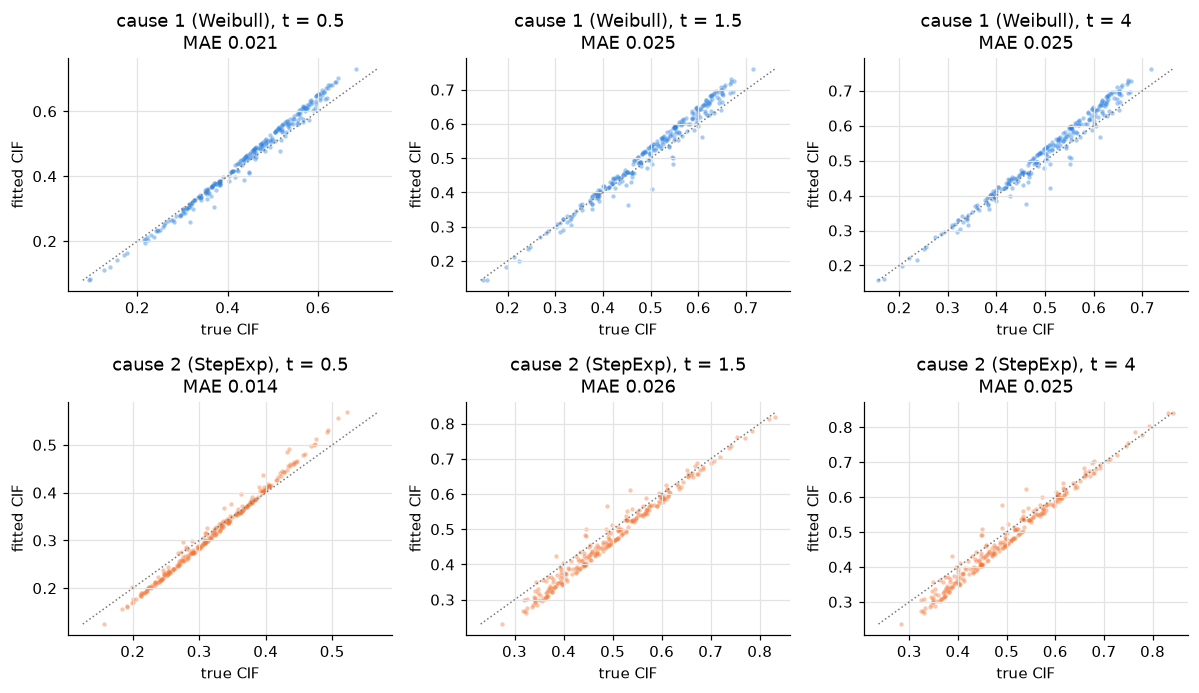

In [90]:
eval_times = np.array([0.5, 1.5, 4.0], dtype=np.float32)


def agreement_grid(mode, label):
    # scatter of true vs fitted values of a cause-specific mode: one row per cause, one column per time
    true_eval = predict(true_model, mode, X_test, eval_times)
    fitted_eval = predictor.predict(mode, X_test, eval_times)
    fig, axes = plt.subplots(n_causes, len(eval_times), figsize=(11, 3.2 * n_causes), squeeze=False)
    for row, k in enumerate(CAUSE_NAMES):
        for col, t in enumerate(eval_times):
            ax = axes[row, col]
            true_values, fitted_values = true_eval[:, col, k - 1], fitted_eval[:, col, k - 1]
            lims = [min(true_values.min(), fitted_values.min()), max(true_values.max(), fitted_values.max())]
            ax.plot(lims, lims, color=NEUTRAL, linewidth=1, linestyle=":")
            ax.scatter(true_values, fitted_values, s=8, alpha=0.4, color=CAUSE_COLORS[k], linewidths=0)
            mae = np.abs(true_values - fitted_values).mean()
            ax.set(title=f"{CAUSE_NAMES[k]}, t = {t:g}\nMAE {mae:.3f}", xlabel=f"true {label}",
                   ylabel=f"fitted {label}")
    fig.tight_layout()
    plt.show()


agreement_grid("latent_survival", "latent survival")
agreement_grid("cif", "CIF")

As a last sanity check, the predicted quantities are consistent: every individual's probability mass is either still
event-free or assigned to exactly one cause, $\sum_k F_k(t) + S(t) = 1$.

In [70]:
cif_all = predictor.predict("cif", X_test, times)
surv_all = predictor.predict("survival", X_test, times)
print(f"max |sum_k F_k + S - 1| = {np.abs(cif_all.sum(axis=-1) + surv_all - 1).max():.2e}")

max |sum_k F_k + S - 1| = 1.19e-07


## Takeaways

- Competing-risks data use **integer cause codes** in the event field of the usual structured target.
- `CompetingRisksSurvivalAdapter` combines one latent survival adapter per cause. Any adapter can be used, and
  outcome-dependent ones (e.g. `StepExpSurvivalAdapter`) are built from the event times of their own cause.
- `CompetingRisksLikelihoodLoss` fits the latent distributions jointly through the exact likelihood, and the modes
  `cif`, `cs_density`, `cs_hazard`, and `latent_survival` expose the cause-specific predictions with a trailing cause
  axis.
- With a correctly specified model the latent distributions and the cumulative incidences are recovered from the data
  alone. Try other entries in `CAUSES` to see how different distributions and numbers of causes behave.
- **Caveat.** Latent distributions are identifiable from competing-risks data only through the **independence
  assumption** of the model: the CIFs are always estimable, but the interpretation of $S_k$ as "the survival without
  the other causes" relies on that assumption.